## Blue Ridge 6LiF run October 2026 deposit SN02

This repeats the work of Run10_26_SN01 on the second deposit, SN02.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from DepositData5 import DepositData

In [3]:
sn02 = DepositData.from_file('Run10_26_SN02.txt', '6LiF on Si')

Using t1
Using t2
Using grading
Using roughness


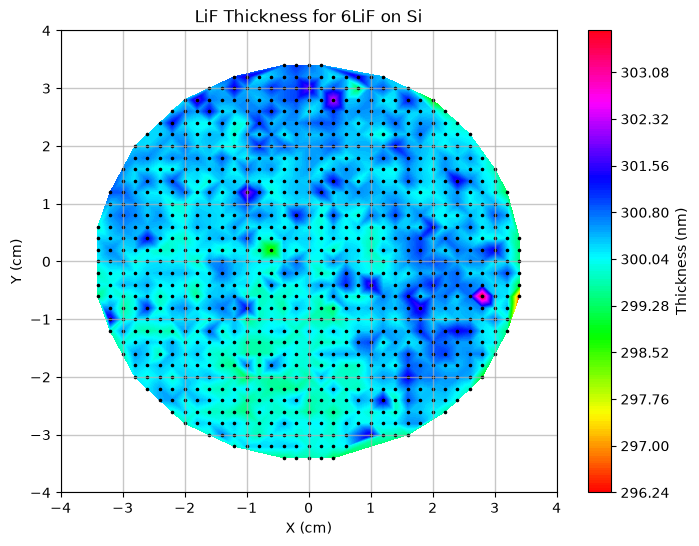

In [4]:
sn02.Ron_plot()

Well that is maybe not quite as pretty as the first one. It may have a bit of a slope.
Let's build the corrected thickness.

In [5]:
zc02 = sn02.t1 + 0.847 * sn02.t2

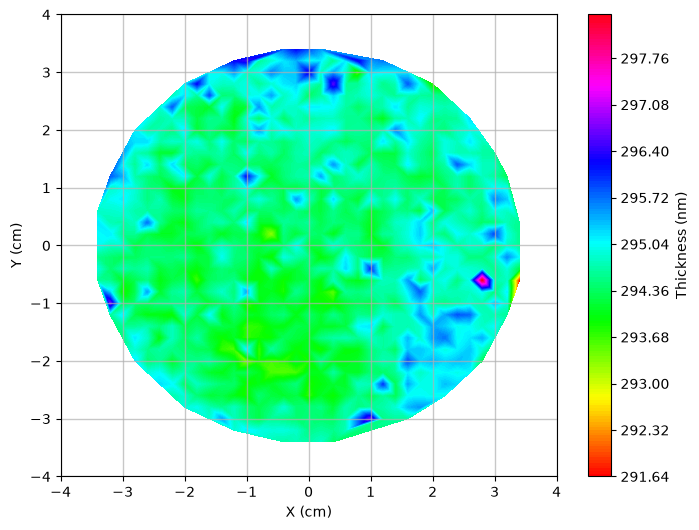

In [6]:
sn02.contour_plot(zc02)

Well, maybe not. That looks pretty darn good.    

Try for the 3-D anyway.

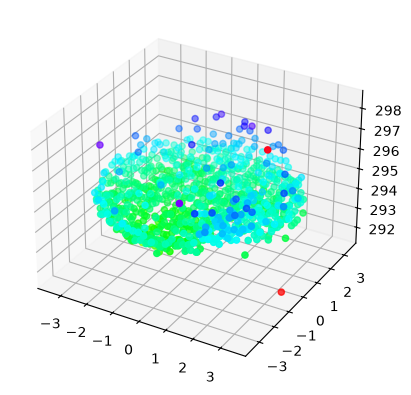

In [7]:
        fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
        surf = ax.scatter(sn02.xdata[sn02.mask], sn02.ydata[sn02.mask], 
                          zc02[sn02.mask], c= zc02[sn02.mask],
                          cmap='hsv')


Well, I don't see much there. It looks flat with noise above and below. that would be brilliant! Let's try a planar fit. First we have to replace the default zdata with our void corrected data.

In [8]:
sn02.zdata = zc02

In [9]:
# Scaled initial parameters
ipg = [ 5.96,  0.0, 0.0]

def planar_fit(p, a):
    return DepositData.fit_helper(p, a, 'angled_plane')

In [10]:
sn02f =sn02.fit_to(planar_fit, ipg)
print(sn02f)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 202.2274422156881
        x: [ 2.946e+02 -2.257e+00  7.887e-02]
      nit: 15
      jac: [ 5.913e-05  6.104e-05  6.123e-04]
 hess_inv: [[ 5.222e-04 -4.434e-05  3.224e-06]
            [-4.434e-05  2.882e-02  6.102e-05]
            [ 3.224e-06  6.102e-05  1.863e-04]]
     nfev: 120
     njev: 30


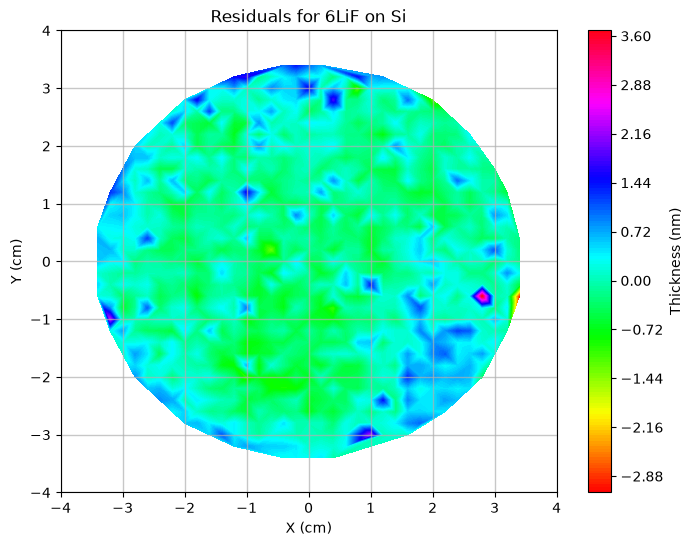

In [11]:
sn02.resid_plot()

Well this one has rather more peak-peak noise than SN01 but the biggest differences are round the extreme edges where we don't care since neutrons will never go there. Indeed most of the difference is a single spot and we know that we don't believe those anyway. This also seems usable.